<a href="https://www.kaggle.com/code/eaganrainmahasin/transfer-learning?scriptVersionId=365600357" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Importing Library dan Configuration

In [1]:
import copy
import glob
import os
import random
import time
import zipfile

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from matplotlib.colors import ListedColormap
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Dataset
from tqdm.auto import tqdm

CFG = {
    "img_size": 256,
    "val_size": 0.15,
    "test_size": 0.15,
    "batch_size": 16,
    "lr": 1e-3,
    "exp_epochs": 15,
    "final_epochs": 40,
    "seed": 42,
}
COLORS = {"blue": "#30AFFF", "cyan": "#92EEFF", "lime": "#D8FFC5", "mint": "#C4F7CA", "bg": "#0B1D2A"}
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


seed_everything(CFG["seed"])

# Tema gelap agar keempat warna palet kontras
plt.rcParams.update({
    "figure.facecolor": COLORS["bg"], "axes.facecolor": COLORS["bg"], "savefig.facecolor": COLORS["bg"],
    "text.color": "white", "axes.labelcolor": "white", "axes.edgecolor": "white",
    "xtick.color": "white", "ytick.color": "white", "axes.titlecolor": "white",
    "legend.facecolor": COLORS["bg"], "legend.labelcolor": "white", "axes.grid": False,
})
print(f"Device: {DEVICE}")

Device: cpu


# Finding Data

In [2]:
def prepare_train_dir(root="/kaggle/input", out="/kaggle/working/stage1_train"):
    zips = glob.glob(f"{root}/**/stage1_train.zip", recursive=True)
    if zips:
        with zipfile.ZipFile(zips[0]) as zf:
            zf.extractall(out)
        return out
    dirs = [d for d in glob.glob(f"{root}/**/stage1_train", recursive=True) if os.path.isdir(d)]
    if not dirs:
        raise FileNotFoundError("stage1_train tidak ditemukan. Tambahkan input kompetisi 'data-science-bowl-2018'.")
    return dirs[0]


TRAIN_DIR = prepare_train_dir()
sample_dirs = sorted(glob.glob(f"{TRAIN_DIR}/*/"))
print(f"{len(sample_dirs)} sampel di {TRAIN_DIR}")

670 sampel di /kaggle/working/stage1_train


# Load Image

In [3]:
def load_sample(sample_dir, size):
    sid = os.path.basename(os.path.normpath(sample_dir))
    image = cv2.cvtColor(cv2.imread(f"{sample_dir}/images/{sid}.png", cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    mask = np.zeros(image.shape[:2], np.uint8)
    for path in glob.glob(f"{sample_dir}/masks/*.png"):
        mask[cv2.imread(path, cv2.IMREAD_GRAYSCALE) > 0] = 1
    image = cv2.resize(image, (size, size), interpolation=cv2.INTER_AREA)
    mask = cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)
    return image, mask


samples = [load_sample(d, CFG["img_size"]) for d in tqdm(sample_dirs, desc="Memuat data")]
X = np.stack([s[0] for s in samples])
Y = np.stack([s[1] for s in samples])
del samples
print(f"X: {X.shape} {X.dtype} | Y: {Y.shape} unik={np.unique(Y)}")

Memuat data:   0%|          | 0/670 [00:00<?, ?it/s]

X: (670, 256, 256, 3) uint8 | Y: (670, 256, 256) unik=[0 1]


# EDA

Citra terang: 124 | gelap: 546
Rasio piksel inti per citra: rata-rata 0.139, min 0.000, maks 0.593


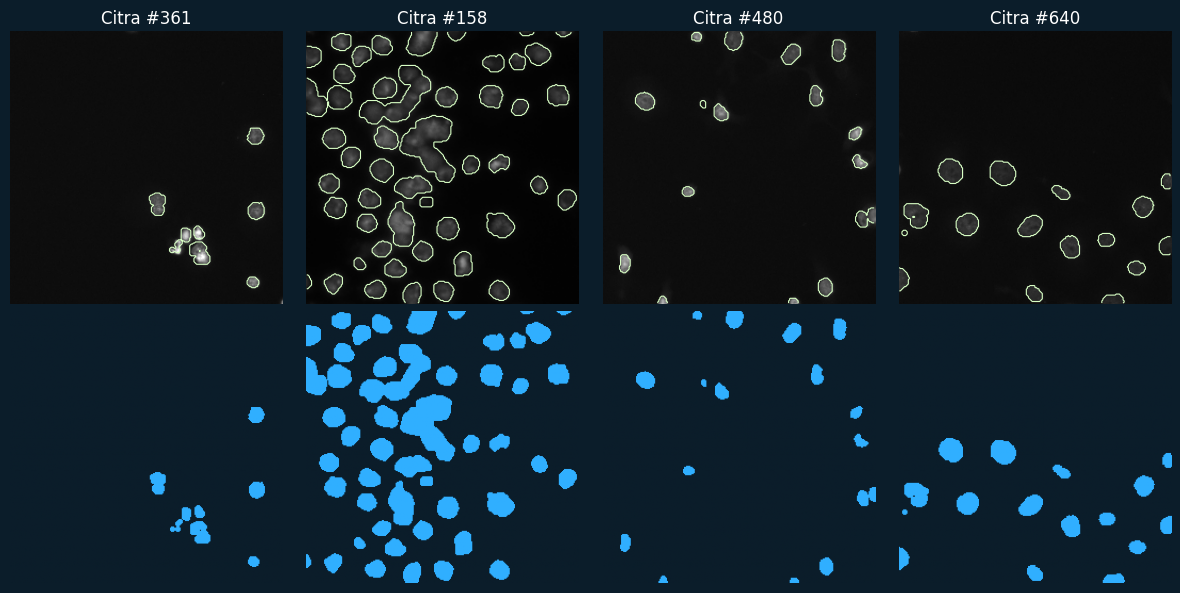

In [4]:
def show_samples(images, masks, n=4):
    idx = np.random.choice(len(images), n, replace=False)
    mask_cmap = ListedColormap([COLORS["bg"], COLORS["blue"]])
    fig, axes = plt.subplots(2, n, figsize=(3 * n, 6))
    for col, i in enumerate(idx):
        axes[0, col].imshow(images[i])
        axes[0, col].contour(masks[i], levels=[0.5], colors=COLORS["lime"], linewidths=0.8)
        axes[1, col].imshow(masks[i], cmap=mask_cmap)
        axes[0, col].set_title(f"Citra #{i}")
    for ax in axes.ravel():
        ax.axis("off")
    plt.tight_layout()
    plt.show()


is_bright = X.mean(axis=(1, 2, 3)) > 100  # heuristik kasar: brightfield/H&E (terang) vs fluoresens (gelap)
coverage = Y.mean(axis=(1, 2))
print(f"Citra terang: {is_bright.sum()} | gelap: {(~is_bright).sum()}")
print(f"Rasio piksel inti per citra: rata-rata {coverage.mean():.3f}, min {coverage.min():.3f}, maks {coverage.max():.3f}")
show_samples(X, Y)